# 1.1 Determining a person's gender and age from a photo


File: man1.jpg


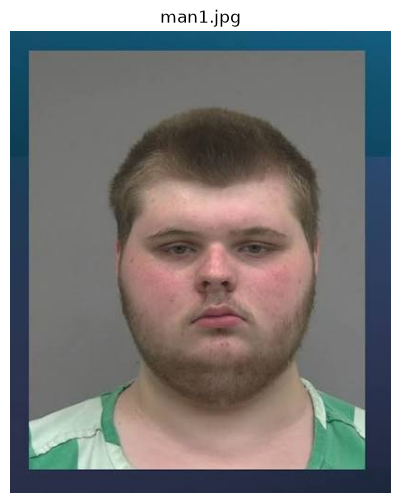

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 15.37it/s]


Face 1: approximate age — 25, gender prediction — Man

File: man2.jpg


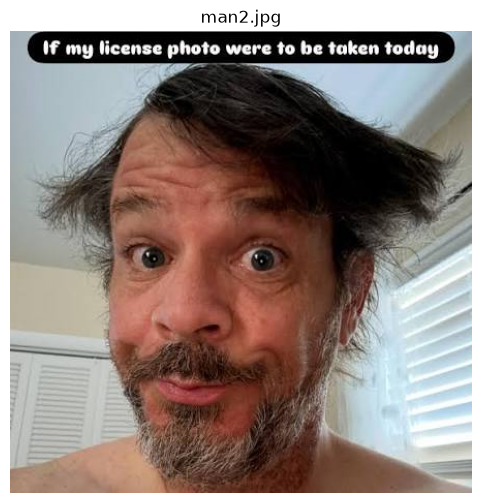

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 15.12it/s]


Face 1: approximate age — 35, gender prediction — Man

File: man3.jpg


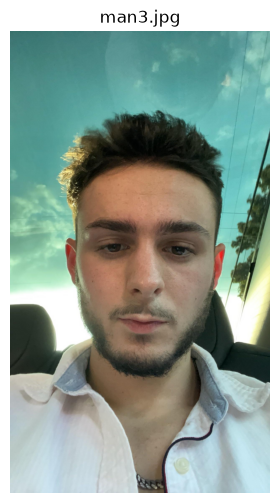

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 12.87it/s]


Face 1: approximate age — 24, gender prediction — Man

File: whoman1.jpg


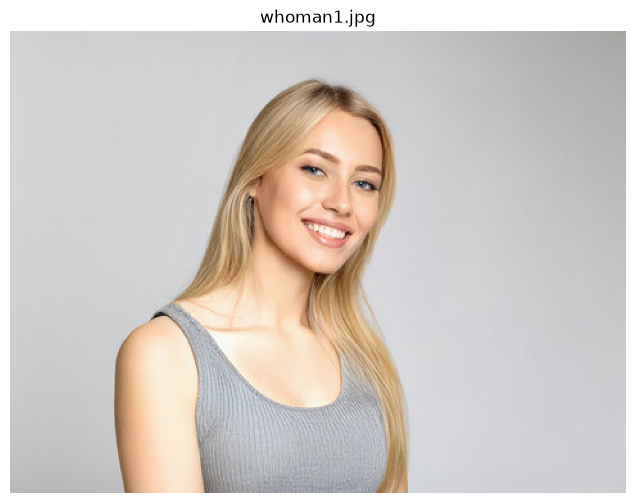

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 19.02it/s]


Face 1: approximate age — 30, gender prediction — Woman

File: whoman2.jpg


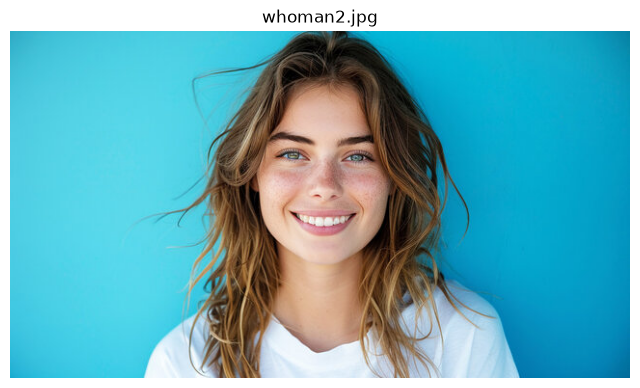

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 17.44it/s]


Face 1: approximate age — 29, gender prediction — Woman

File: whoman3.jpg


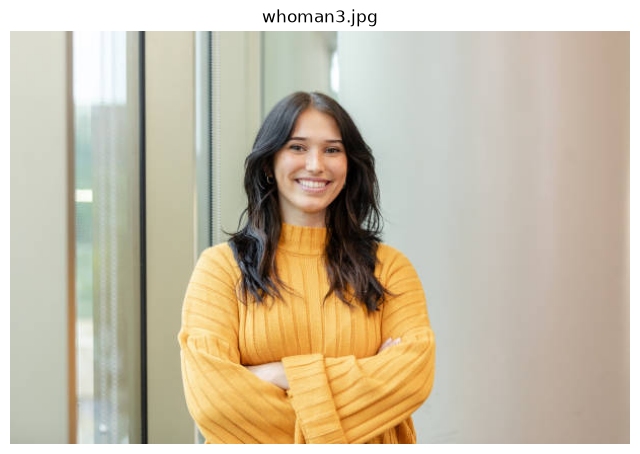

Action: gender: 100%|██████████| 2/2 [00:00<00:00, 15.86it/s]

Face 1: approximate age — 28, gender prediction — Woman


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
from deepface import DeepFace

photos_dir = Path("photos")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not photos_dir.is_dir():
    raise FileNotFoundError(f"Catalog not found: {photos_dir.resolve()}")

image_paths = sorted(
    path for path in photos_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)

if not image_paths:
    raise FileNotFoundError(
        f"No images found in the catalog {photos_dir.resolve()} "
        "with supported extensions: jpg, jpeg, png, bmp, webp"
    )

for image_path in image_paths:
    print(f"\nFile: {image_path.name}")

    image = plt.imread(image_path)
    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

    try:
        analysis = DeepFace.analyze(
            img_path=str(image_path),
            actions=["age", "gender"],
            detector_backend="opencv",
        )
    except ValueError as error:
        print(f"Failed to recognize a face in the image: {error}")
        continue

    faces = analysis if isinstance(analysis, list) else [analysis]
    for face_number, face in enumerate(faces, start=1):
        print(
            f"Face {face_number}: approximate age — {face['age']:.0f}, "
            f"gender prediction — {face['dominant_gender']}"
        )